# 같은 물량, 다른 가격

**관세와 소액면세 중단 이후 K-뷰티 대미 공급망에서 미국 통계가 놓친 것**

1. **누구의 문제인가.** 미국 현지 창고에 재고를 두고 파는 K-뷰티 브랜드의 SCM 담당자다. 2025년 8월 한국산에 15% 상호관세가 붙고(8/7) 미국 소액면세가 모든 국가에 대해 중단됐다(8/29).
2. **어떤 결정을 내려야 하나.** 정책 이후 물량·가격 신호를 어떻게 읽을지, 앞으로 몇 달의 흐름을 무엇으로 가늠할지, 어느 항만으로 들여와 재고를 얼마나 둘지다.
3. **무엇을 발견했나.** 미국 통계만 보면 상품이 싸지고 물량이 늘었다. 그러나 같은 흐름을 기록한 한국 수출 통계와 맞대자, **두 나라가 반대 방향의 가격을 기록하고 있었다**(kg당 한국 +8%, 미국 −20%).
4. **분석으로 무엇이 바뀌었나.** "상품이 싸졌다"는 처음 해석을 버렸다. 그 대신 미국 단가를 단독으로 읽지 않는 규칙, 의사결정 기간별 예측 규칙, 내륙 운송 일수에 따른 항만 선택 기준을 만들었다.

공개 데이터 7개 원천(기관 5곳), 2024.01~2026.08. 판정 기준은 데이터를 받기 전에 [사전 등록](../docs/preregistration.md)했다.

In [1]:
import pandas as pd
from IPython.display import Image, display

from kbeauty.paths import FIGURES_DIR, REPO, TABLES_DIR

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)
show = lambda name: display(Image(filename=str(FIGURES_DIR / f"{name}.png")))
tbl = lambda name: pd.read_csv(TABLES_DIR / f"{name}.csv")

## 핵심 결과 1. 같은 흐름이 한국에서는 더 비싸게, 미국에서는 더 싸게 기록됐다

`OBSERVED` 두 나라 통계의 kg당 금액 · `ESTIMATED` 비율의 수준 이동 검정

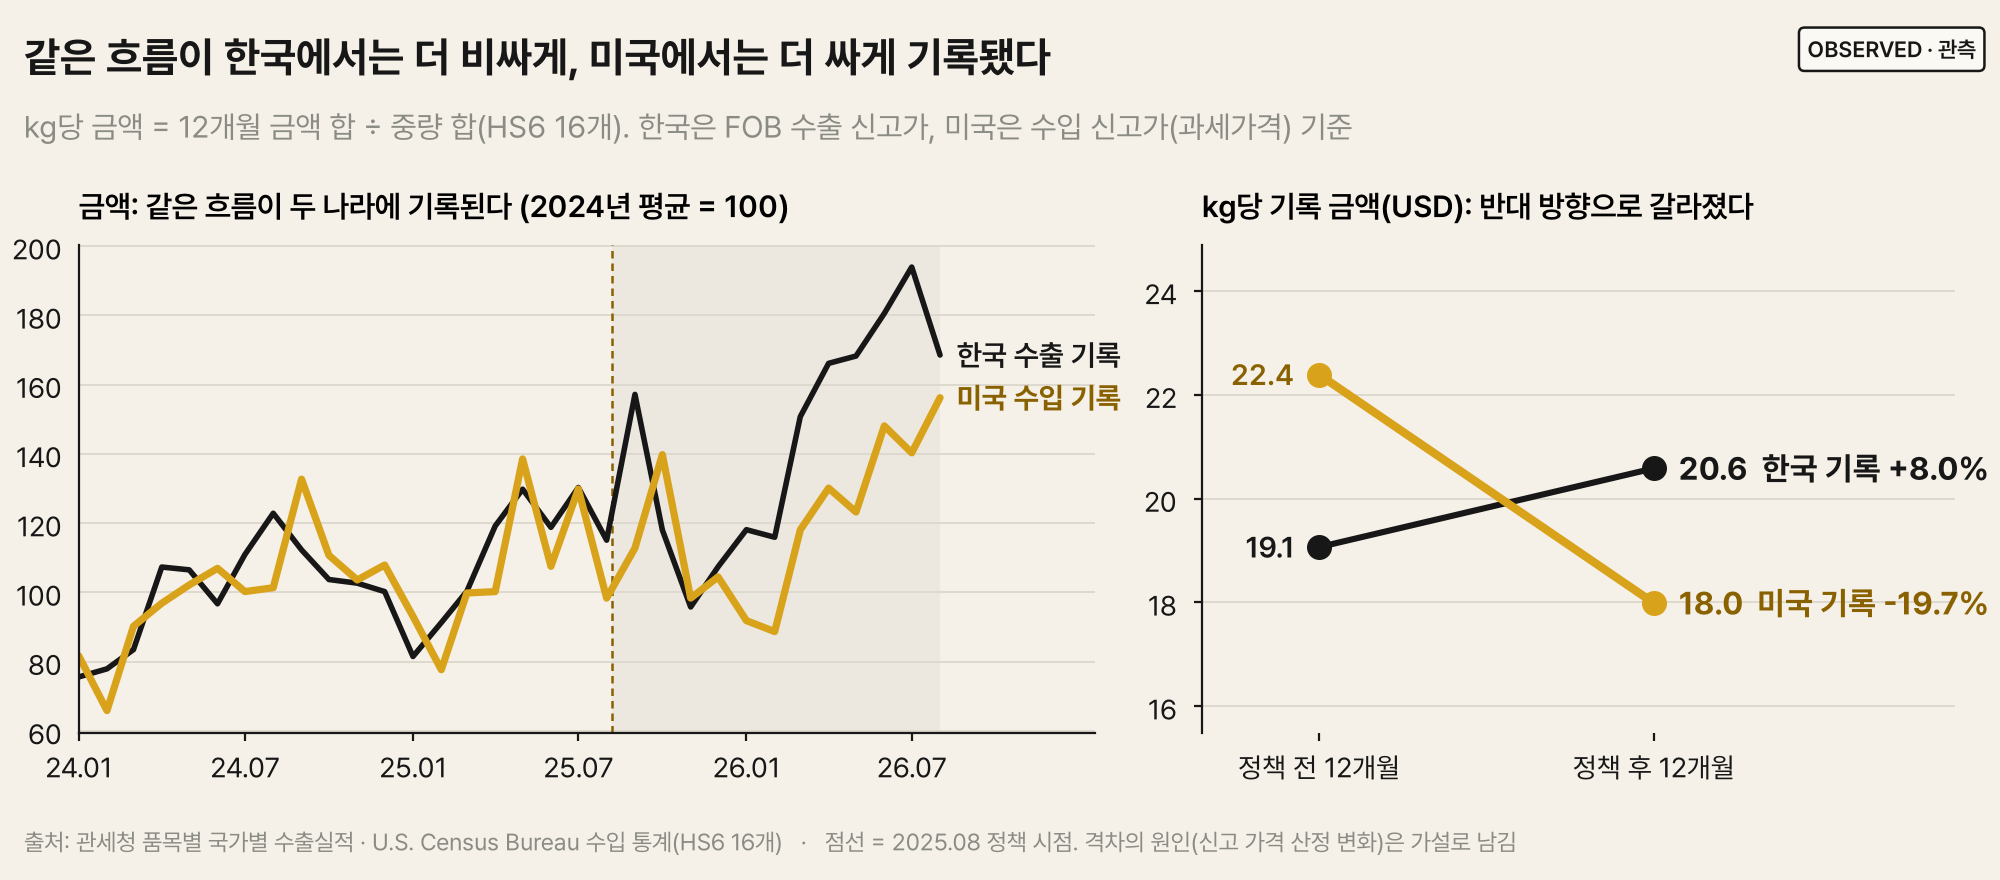

In [2]:
show("12_mirror_same_flow_different_price")

- 정책 후 12개월 kg당 금액은 한국 기록 **+8.0%**, 미국 기록 **−19.7%다**(HS6 16개 합계).
- 소포가 미국 통계에 새로 잡혔다면 미국/한국 비율이 올라야 하는데 오히려 **−14%**(HAC p 0.005)다. 소포 가설은 지지되지 않는다.
- 환율은 미국 측 하락의 10~23%만 설명하고, 한국 측 상승은 비싼 품목으로의 구성 이동이다. 남는 설명은 미국 측 신고 가격의 변화다(`INFERRED`, 통관 건별 자료 없이는 확정할 수 없다).

## 핵심 결과 2. 검증으로 고른 머신러닝은 직전 값과 통계적으로 구분되는 개선을 입증하지 못해 기준선을 유지했다

`ESTIMATED` rolling-origin 백테스트(기준 시점 8개)

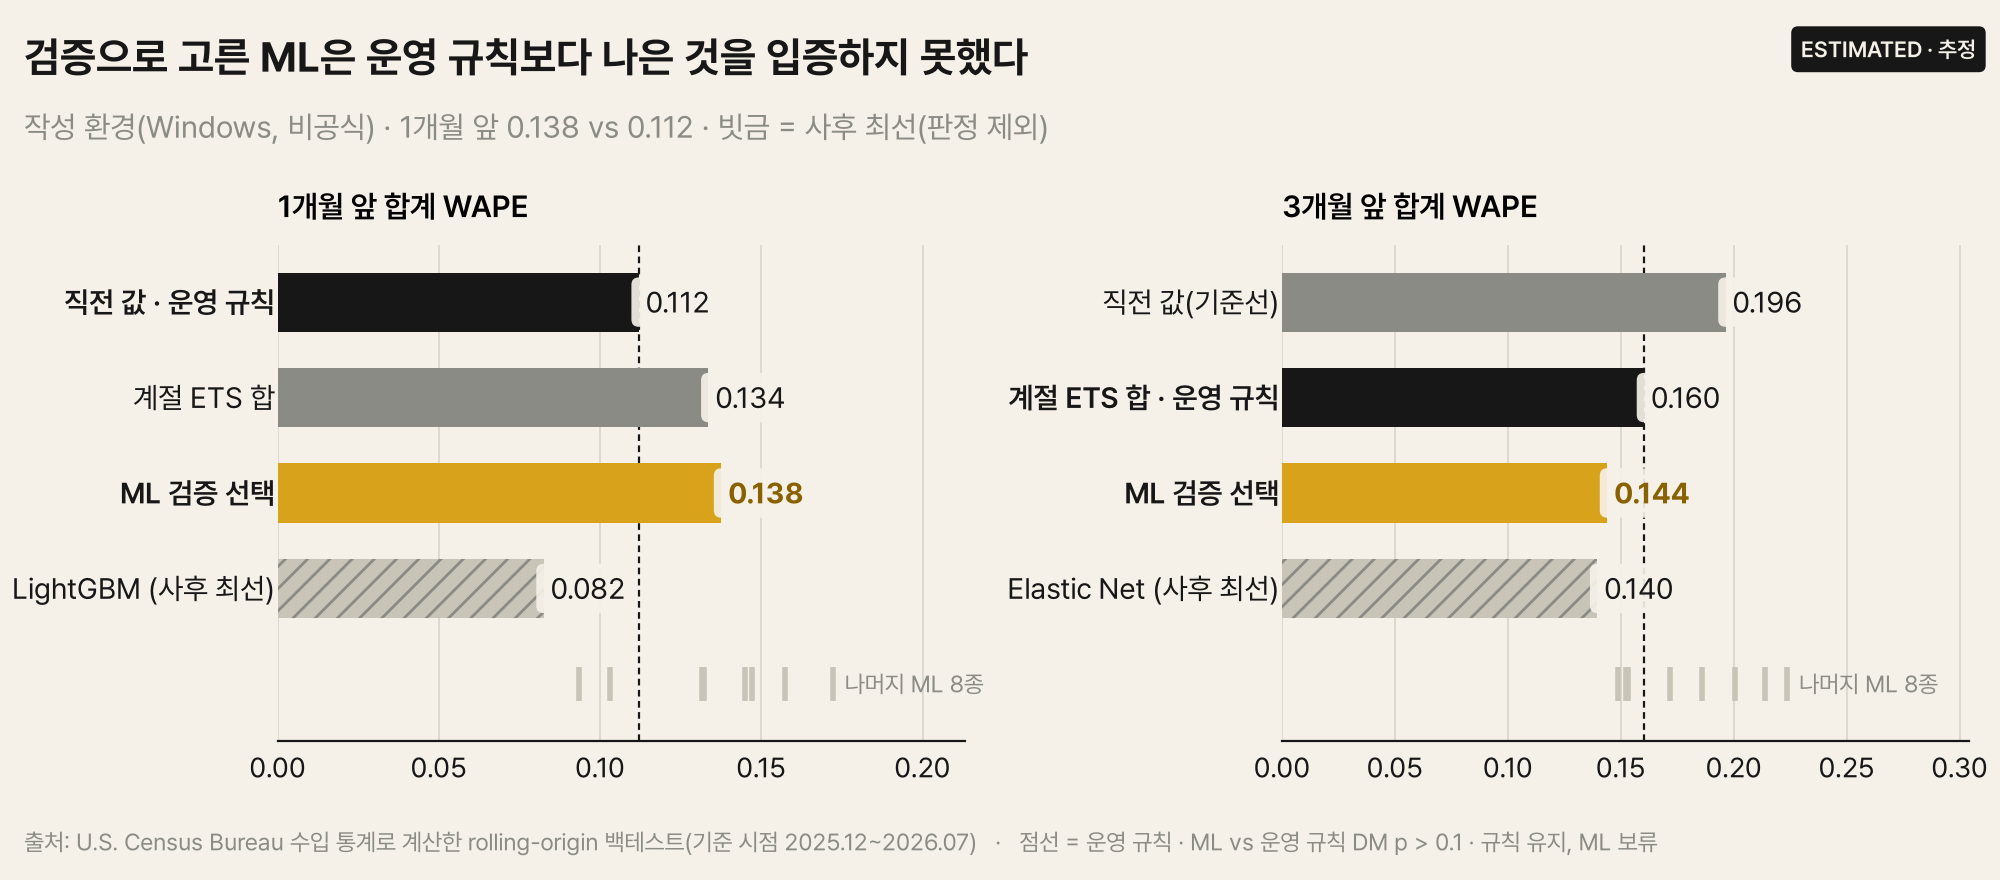

In [3]:
show("15_ml_comparison")

- 1개월 앞은 **직전 값**(합계 WAPE 0.112), 3개월 앞은 **계절 ETS를 품목·운송수단별로 예측해 더한 것**(0.160)이 운영 규칙이다.
- 머신러닝 9종 76개 설정을 같은 조건에서 비교했다. 최근 3개월 검증 성적으로 고른 모델은 1개월 앞 0.109로 직전 값 0.112보다 낮았지만, 차이가 통계적으로 구분되지 않아(DM p 0.91) 직전 값 기준선을 유지했다(공식 기준: Linux 고정 환경). 3개월 앞(0.144)도 계절 ETS와 구분되지 않는다(DM p 0.87). **머신러닝은 보류**했다.
- 위 그림과 이 노트북의 표는 작성 환경(Windows) 결과다. 여기서는 1개월 앞이 0.138로 공식 기준과 다르며, 진단 이력으로 남긴다(모델 카드 8절).
- 부스팅 3종은 1개월 앞 0.082~0.103이었지만 시험 구간을 보고 고른 사후 비교다. 2026-09~11 예측을 공개 전에 고정해 두었고, Census 공개 후 채점해 판정한다. → [모델 카드](../reports/model_card.md)

## 핵심 결과 3. 해상 수입 금액의 82%가 LA·롱비치에 몰려 있다

`OBSERVED` 하역항 비중 · `SCENARIO` 중단 노출액, 경로 손익분기

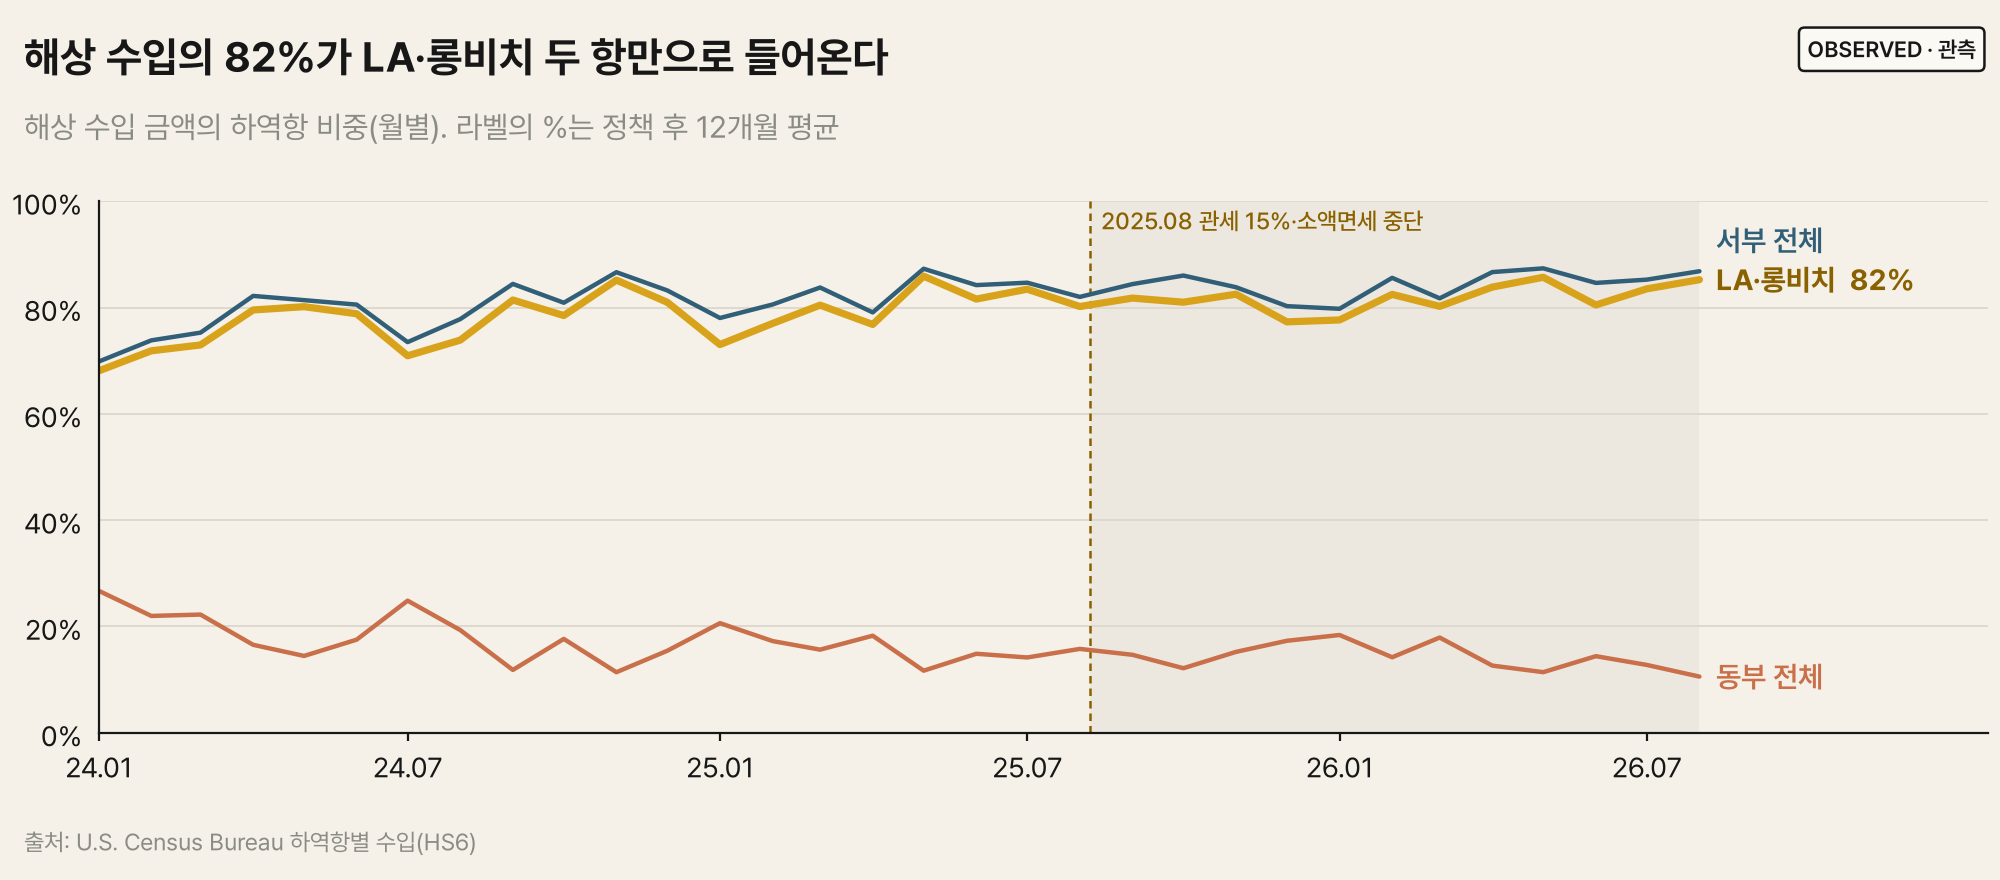

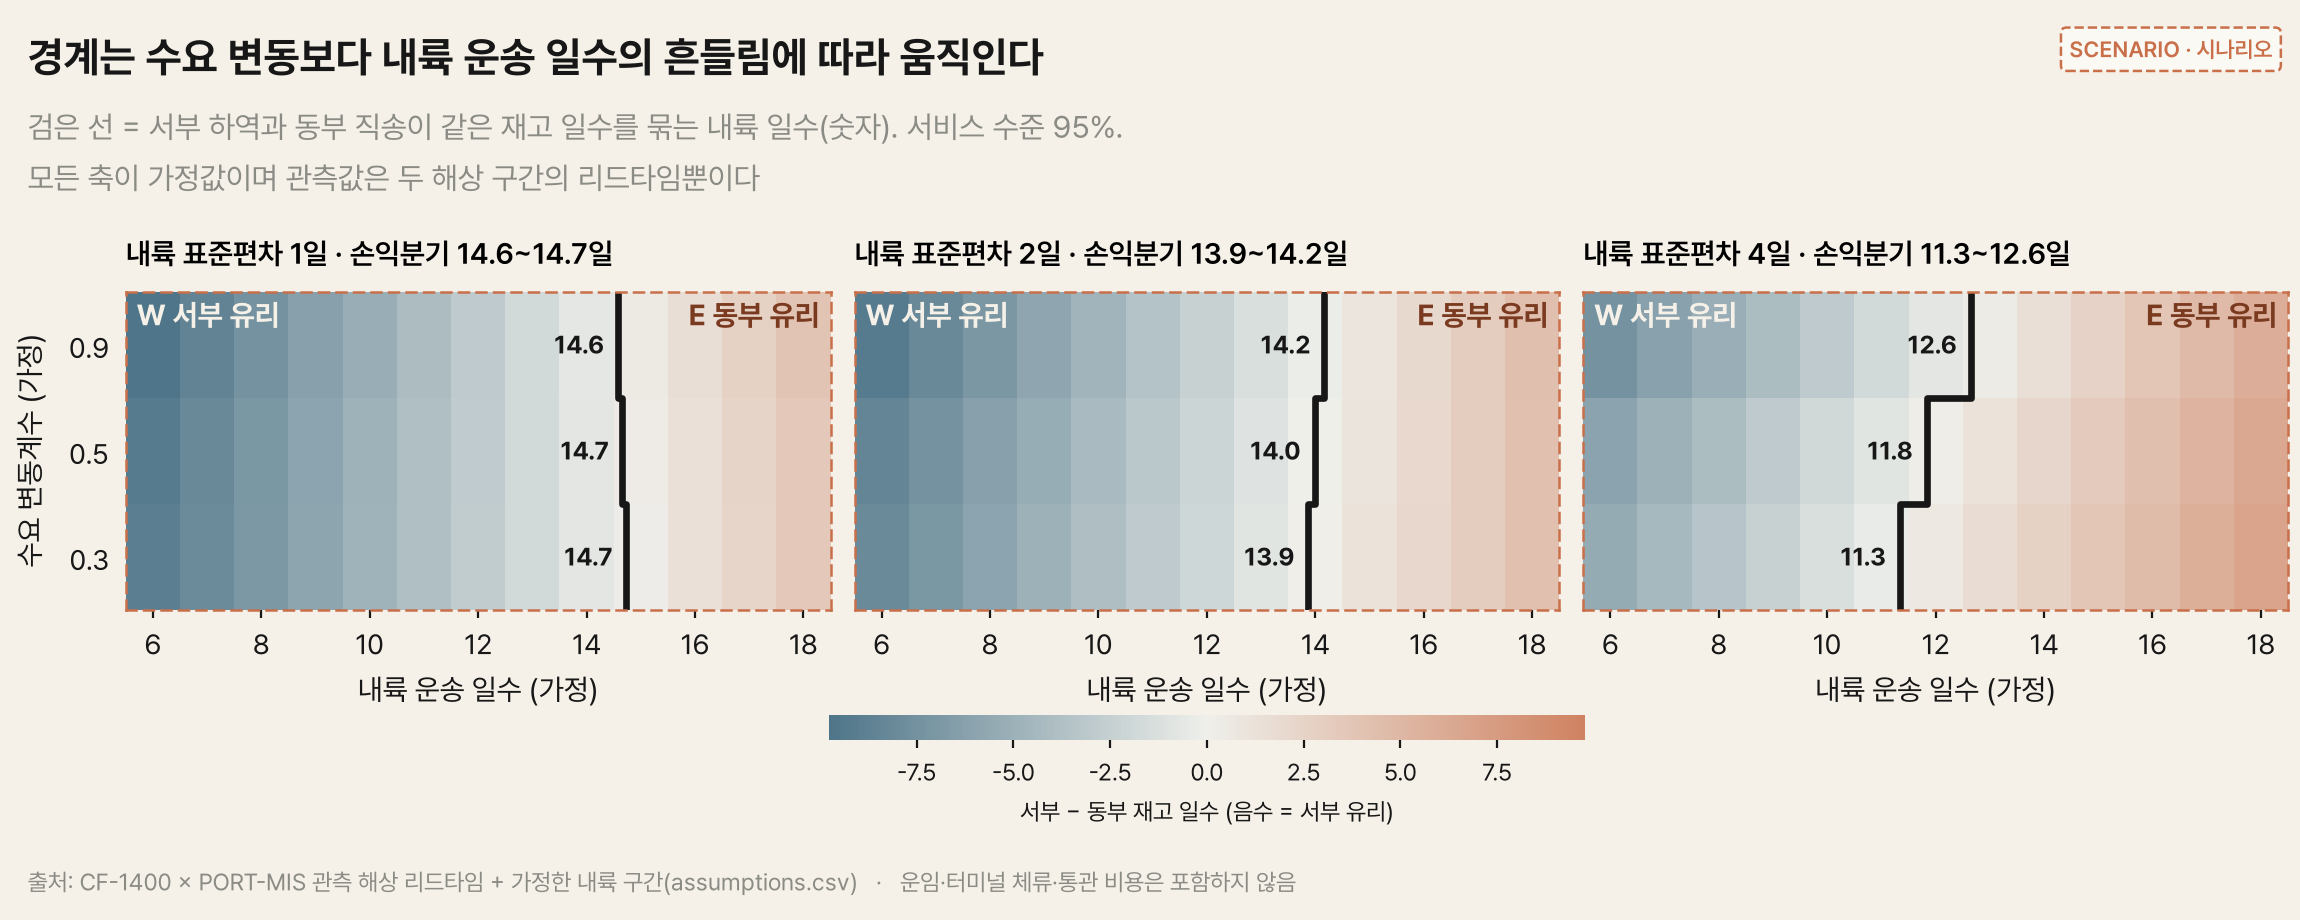

In [4]:
show("06_port_concentration")
show("16_route_sensitivity")

- LA·롱비치 2주 중단은 해상 수입 약 **5,500만 달러**의 지연이다(시나리오: 중단 기간, 하역 비중 일정 가정).
- 동부 수요를 서부 하역 + 내륙 운송으로 채우는 경로는 내륙 운송이 **약 14일 이하**일 때 재고를 덜 묶는다. 이 경계는 수요 변동보다 **내륙 일수의 흔들림**에 민감하다(표준편차 1일이면 14.6~14.8일, 4일이면 10.1~13.0일).
- 정책 후 해상 리드타임 자체는 변하지 않았다(`ESTIMATED`, 사전 등록 Q5).

## 운영 규칙: 이 분석의 최종 결과

결정마다 조건, 권고, 근거 주장(아래 표의 ID), 근거 수준, 불확실성, 한계를 함께 둔다. 숫자는 모두 결과 표에서 자동으로 읽는다(`reports/tables/decision_recommendations.csv`).

In [5]:
tbl("decision_recommendations")[["decision", "condition", "recommendation", "evidence", "evidence_level", "uncertainty", "limitation"]]

,decision,condition,recommendation,evidence,evidence_level,uncertainty,limitation
0,단가 해석,미국 kg당 단가가 떨어졌을 때,"미국 단가만으로 '상품이 싸졌다'고 판단하지 않는다. 한국 수출 단가와 함께 보고, 두 기록의 격차를 별도 지표로 관리한다","C02, C05, C06, C07","hypothesis, observed",격차의 원인은 가설(C07),통관 건별 자료 없이 원인 미확정
1,1개월 앞 외부 흐름,다음 달 미국 수입 흐름을 발주 판단의 참고로 볼 때,직전 값을 기준선으로 쓴다(합계 WAPE 0.112). 정책 충격 직후에는 '작년 같은 달'을 쓰지 않는다(WAPE 0.187),"C09, C11",estimated,"1개월 앞 순위는 미확정(DM p 0.17), 80% 구간 과소 포함","공개 수입통계(미국 Census 기록 금액)의 예측이다. 기업 내부 판매·재고·발주 데이터를 쓰는 수요예측이 아니며, 발주 판단을 돕는 외부 시장 흐름 지표로만 쓴다."
2,3개월 앞 외부 흐름,분기 물량·운송 계획의 참고로 볼 때,계절 ETS를 품목·운송수단별로 예측해 더한다(WAPE 0.160). 머신러닝은 고정 예측 채점에서 우위가 확인될 때까지 보류한다,"C09, C10, C11",estimated,ML 선택 모델 0.144와 구분 불가(DM p 0.87),"공개 수입통계(미국 Census 기록 금액)의 예측이다. 기업 내부 판매·재고·발주 데이터를 쓰는 수요예측이 아니며, 발주 판단을 돕는 외부 시장 흐름 지표로만 쓴다."
3,하역 권역,동부 수요를 서부 하역 + 내륙 운송으로 채울지 판단할 때,"내륙 운송 일수가 손익분기 이하이면 서부 하역, 넘으면 동부 직송. 손익분기는 내륙 일수의 흔들림에 가장 민감하다(표준편차 1일 14.6~14.8일, 4일 10.1~13.0일)","C08, C15","estimated, scenario",손익분기 전체 범위 10.1~14.8일(가정 조합),재고 일수만 비교(운임·터미널 체류·통관 제외)
4,항만 집중,성수기 전 서부 창고 재고 수준을 정할 때,"LA·롱비치 집중도를 별도 리스크 지표로 관리하고, 2주 중단에 대비한 안전재고 또는 대체 항만을 검토한다","C13, C14","observed, scenario","노출 2,751만 달러~11,788만 달러(7~30일)","시나리오: 중단 기간·비중 일정 가정, 대체 항만 전환비 미포함"


**주장과 근거 수준**: `observed` 관측(또는 관측값의 항등식), `estimated` 통계적 검정·모형, `scenario` 관측되지 않은 가정의 계산, `hypothesis` 검증할 수 없는 해석. 인과 주장은 하나도 하지 않는다.

In [6]:
tbl("claims")[["claim_id", "claim", "value", "evidence_level", "robustness_status"]]

,claim_id,claim,value,evidence_level,robustness_status
0,C01,정책 후 12개월 미국 수입 금액과 중량이 함께 늘었다,"금액 +11.7%, 해상+항공 중량 +39.5%",observed,해당 없음(집계)
1,C02,"미국 기록 kg당 단가가 떨어졌고, 하락의 대부분은 같은 품목 안의 단가 변화다","해상 -16.9%, 항공 -36.0%; 품목 내 몫 78~87%",observed,항등식 검증 통과
2,C03,미국 측 변화는 한국만의 변화로 판정되지 않는다,지표 5개 모두 Holm 보정 p ≥ 0.05(최소 0.38); 평행 추세 위반 2개,estimated,부분: 평행 추세 충족 지표 3개만 해석
3,C04,소포가 미국 통계에 새로 잡혔다는 가설은 지지되지 않는다,미국/한국 금액 비율 -14.1% (HAC p 0.005),estimated,부분: 시간 위약 p 0.36(최대 전환점 2026-01)
4,C05,"같은 흐름이 한국에서는 더 비싸게, 미국에서는 더 싸게 기록됐다","kg당 금액 한국 +8.0%, 미국 -19.7%",observed,세분 수준(HS6·HSK10·HS10)과 무관하게 같은 방향
5,C06,환율은 미국 측 달러 단가 하락의 일부만 설명한다,"해상 23%, 항공 10%, 해상+항공 20%",observed,항등식
6,C07,남는 설명은 미국 측 신고 가격(과세가격 산정)의 변화다,C04~C06으로 소포·환율·구성 설명을 제거한 뒤 남는 가설,hypothesis,검증 불가(통관 건별 자료 필요)
7,C08,정책 전후 해상 리드타임은 변하지 않았다,서부 +0일(95% CI +0~+0); 걸프 +0일(95% CI -1~+1); 동부 -1일(95% CI -2~+1),estimated,세 권역 모두 CI가 0 포함
8,C09,"외부 흐름 예측은 1개월 앞 직전 값, 3개월 앞 계절 ETS(품목·운송수단별 합)가 가장 정확했다","합계 WAPE 1개월 0.112, 3개월 0.160",estimated,"부분: 3개월 앞 우위만 DM p 0.001, 1개월 앞 p 0.17"
9,C10,"머신러닝 9종을 검증 성적으로 고른 모델은 운영 규칙과 통계적으로 구분되는 개선을 입증하지 못해 운영 규칙(1개월 직전 값, 3개월 계절 ETS 합)을 유지했다(ML 채택 보류)","[작성 환경(Windows, 비공식)] 1개월 0.138, 3개월 0.144; 부스팅 1개월 0.082~0.103(사후 비교)",estimated,"부분: 모든 차이 DM p > 0.1, 고정 예측(2026-09~11) 채점 대기"


---

## 어떻게 이 결론에 왔나

분석은 미국 통계의 이상 신호에서 시작해, 처음 해석을 하나씩 반박하는 순서로 진행했다.

| 단계 | 질문 | 답 | 노트북 |
|---|---|---|---|
| 1 | 무엇이 보였나 | 금액 +11.7%, 중량 +39.5%, kg당 단가 하락 | [`01`](01_data_overview.ipynb), [`02`](02_unit_value.ipynb) |
| 2 | 한국만의 변화인가 | 아니다. 기준을 통과한 지표 없음 | [`03`](03_cross_country.ipynb) |
| 3 | 통계에 새로 잡힌 소포인가 | 아니다. 미국/한국 비율 −14% | [`04`](04_mirror.ipynb) |
| 4 | 환율·품목 구성 때문인가 | 일부만. 환율 10~23%, 한국 측 상승은 구성 이동 | [`02`](02_unit_value.ipynb) |
| 5 | 그래서 무엇으로 예측하나 | 1개월 직전 값, 3개월 계절 ETS 합, ML 보류 | [`05`](05_forecasting.ipynb) |
| 6 | 담당자는 무엇을 바꾸나 | 항만 집중 관리, 내륙 일수 기준의 경로 선택 | [`06`](06_decision.ipynb) |

### 1. 이상 신호: 물량은 늘고, 미국 기록의 kg당 단가는 떨어졌다

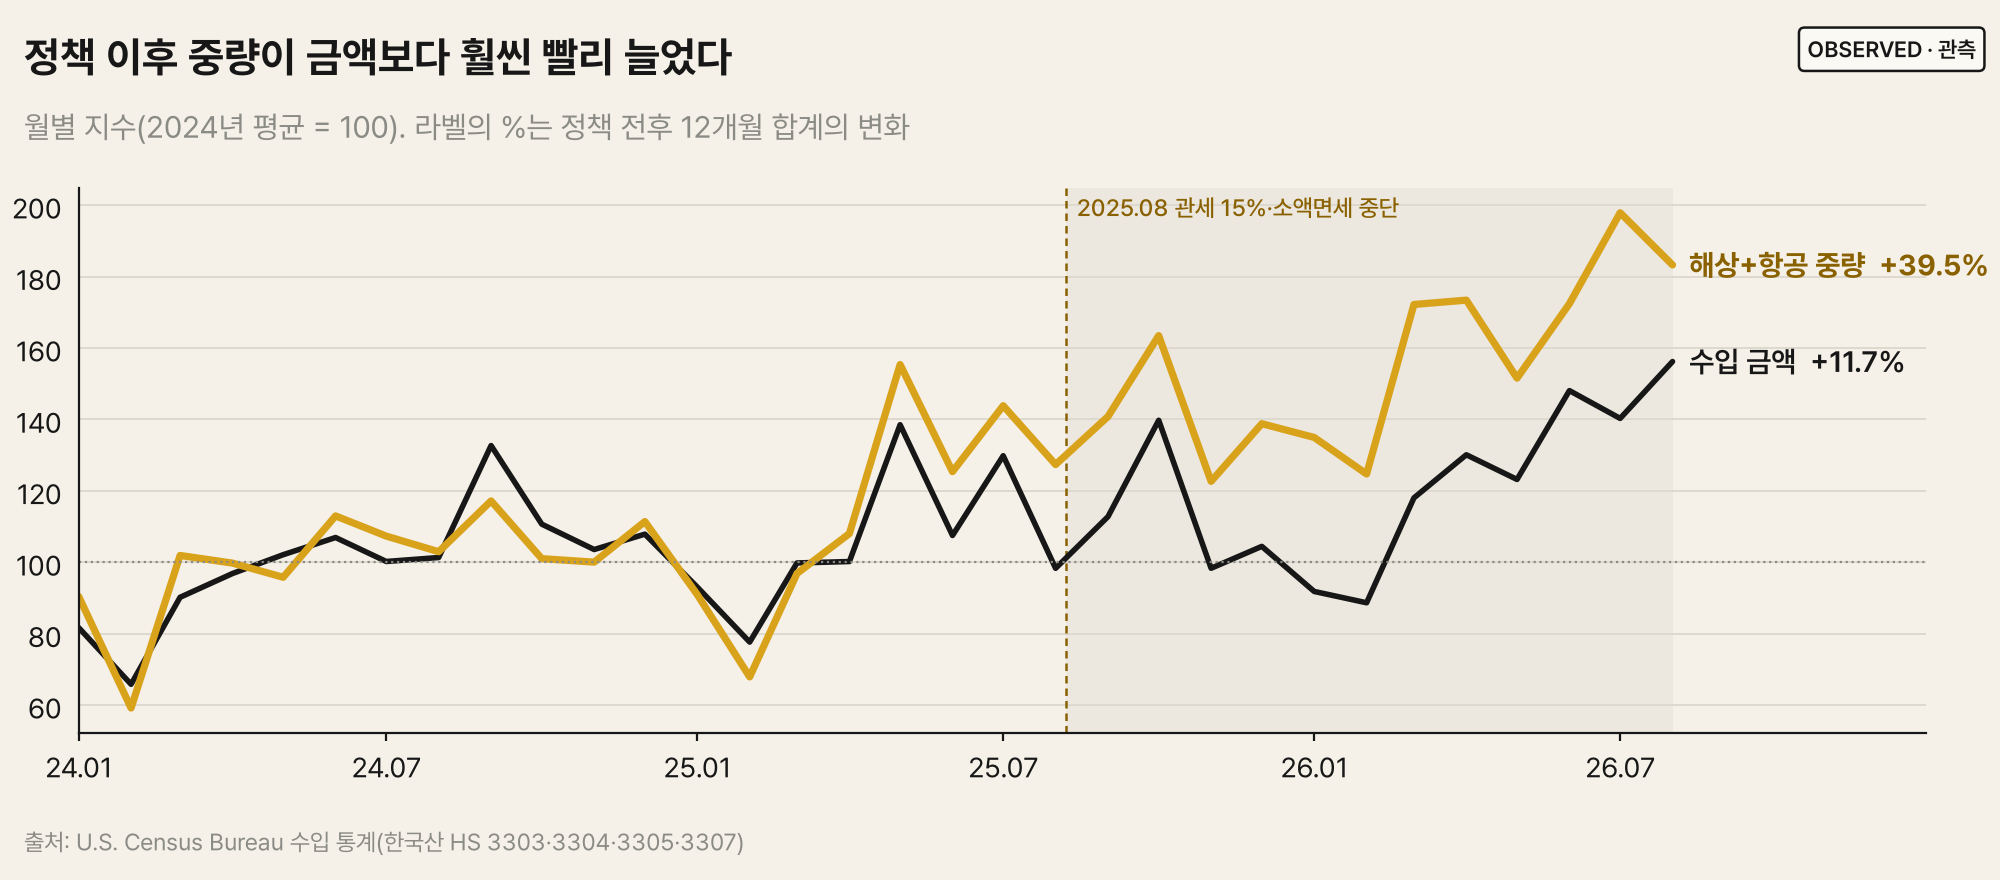

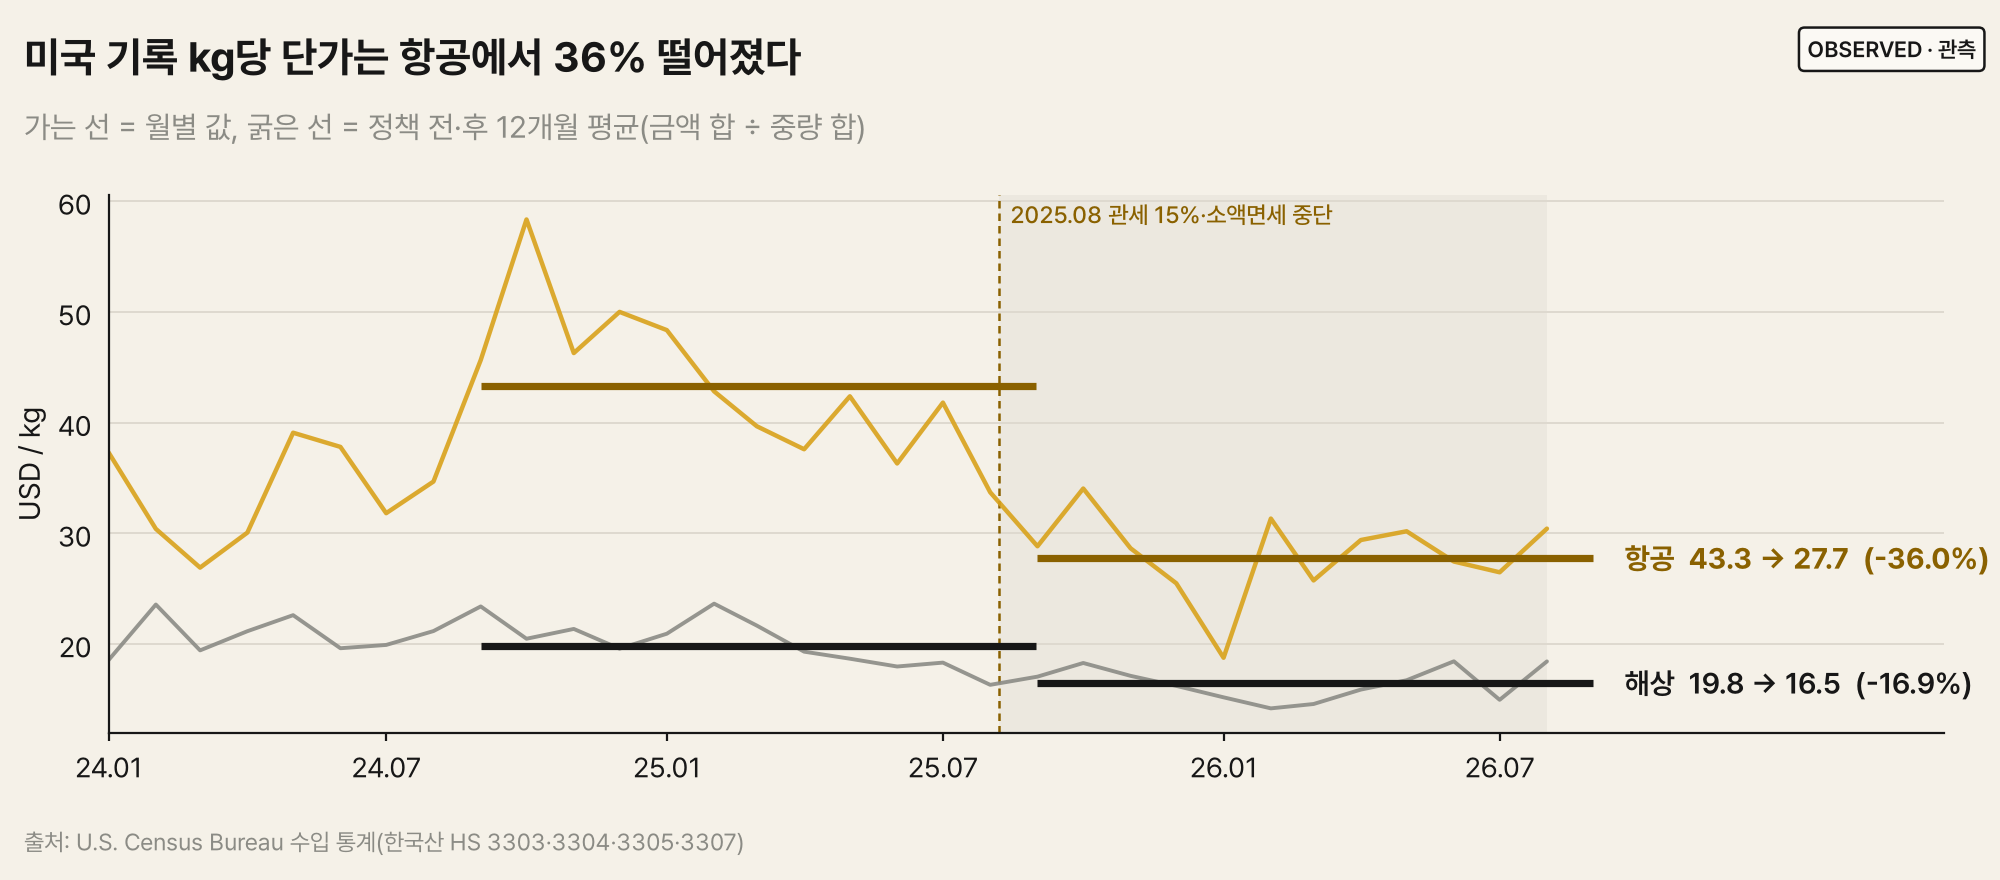

,metric,pre_12m,post_12m,change_pct
0,value_usd,"2,002,910,215.000","2,237,194,247.000",0.117
1,vessel_value_usd,"1,559,119,254.000","1,753,079,446.000",0.124
2,air_value_usd,"419,573,212.000","463,950,210.000",0.106
3,vessel_weight_kg,"78,706,245.000","106,534,601.000",0.354
4,air_weight_kg,"9,680,521.000","16,725,135.000",0.728
5,measured_weight_kg,"88,386,766.000","123,259,736.000",0.395
6,vessel_usd_per_kg,19.809,16.455,-0.169
7,air_usd_per_kg,43.342,27.740,-0.360
8,air_share_weight,0.110,0.136,0.239


In [7]:
show("01_value_vs_weight")
show("02_unit_values")
tbl("window_totals")

정책 후 12개월 미국 기록 기준 수입 금액은 20.0억 → 22.4억 달러(+11.7%), 해상+항공 중량은 8,839만 → 1억 2,326만 kg(+39.5%)이다.
kg당 단가는 해상 19.81 → 16.46달러(−16.9%), 항공 43.34 → 27.74달러(−36.0%). 하락의 78~87%가 같은 HS10 품목 안에서 일어났다.
미국 기록만 보면 "더 싸게, 더 많이"다. **상품이 실제로 싸졌는가, 통계에 잡히는 흐름이 달라졌는가?** 아래 2~4가 이 질문을 점검한다.

### 2. 한국만의 변화인가 — 8개국 비교

비교국은 데이터를 받기 전에 정한 규칙(2024년 미국의 HS 3304 수입액 상위 8개국)으로 골랐다. 처리군이 한국 하나라 국가 × 시점 위약 순위로 추론했다.

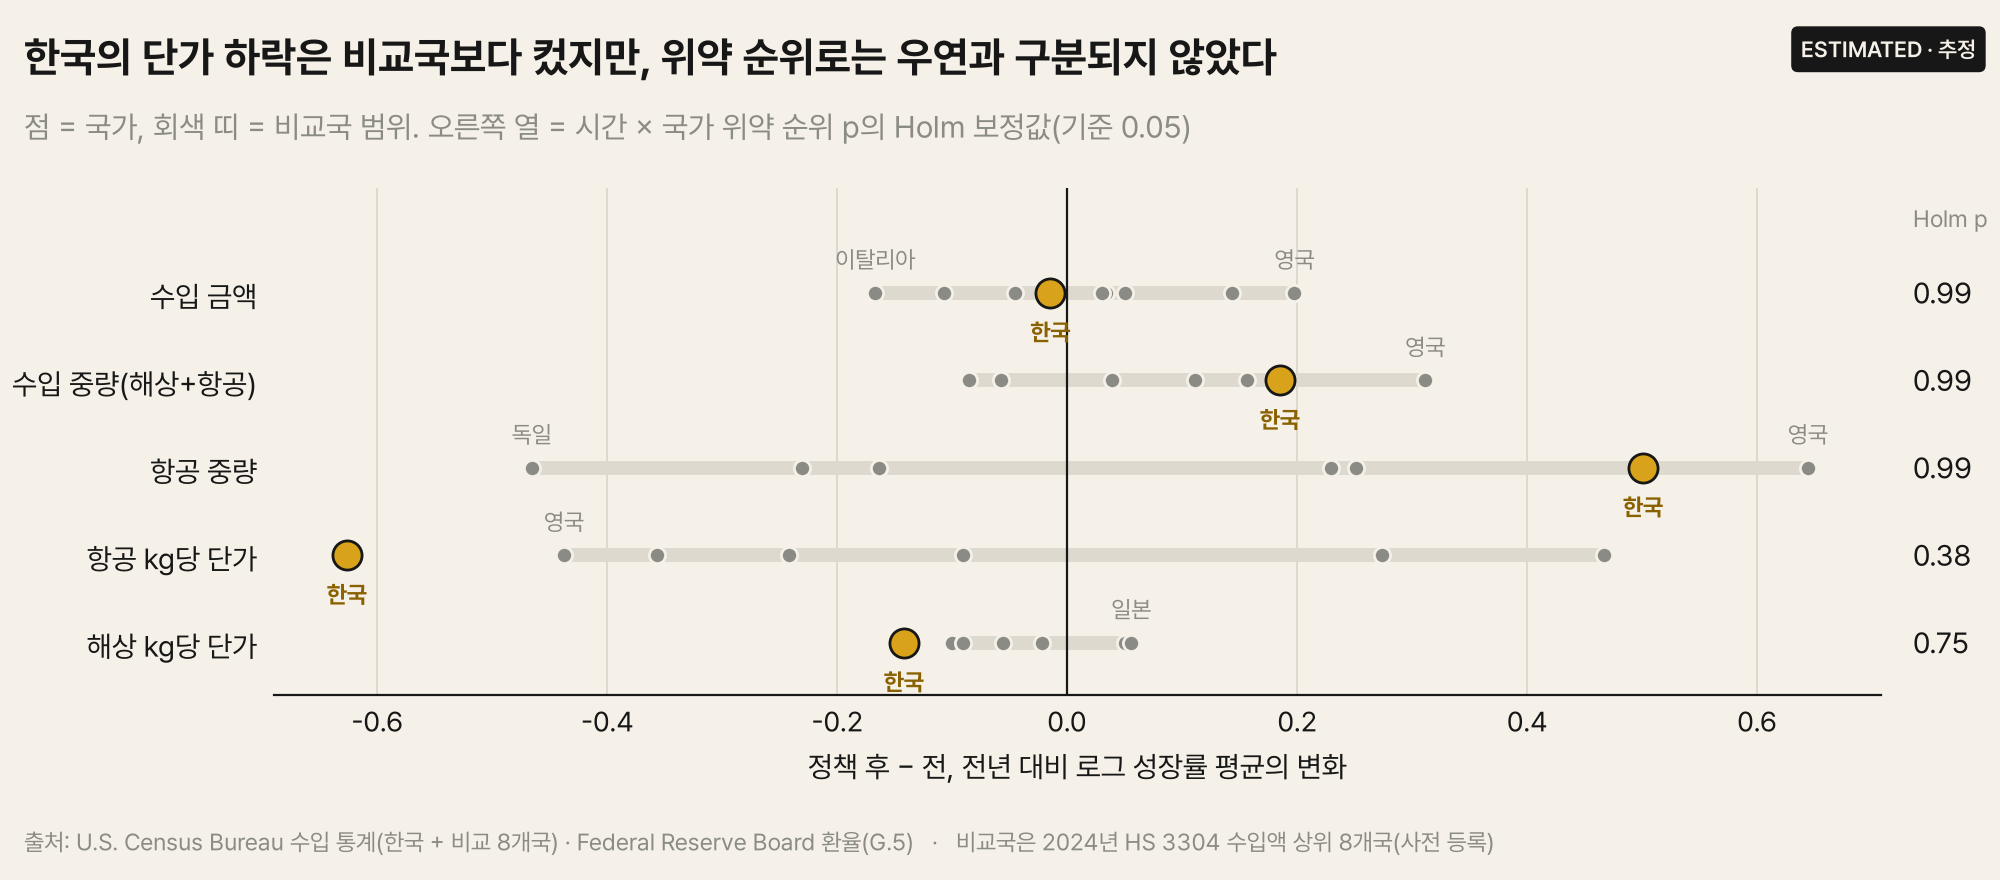

,label,beta_fx_adjusted,p_space_time,p_holm,mde_80pct_power,parallel_trends_ok
0,수입 금액,-0.010,0.923,0.989,0.352,True
1,수입 중량(해상+항공),0.112,0.451,0.989,0.430,False
2,항공 중량,0.461,0.330,0.989,1.221,True
3,항공 kg당 단가,-0.551,0.077,0.385,0.936,True
4,해상 kg당 단가,-0.118,0.187,0.747,0.234,False


In [8]:
show("09_country_shifts")
tbl("comparison_did")[["label", "beta_fx_adjusted", "p_space_time", "p_holm", "mde_80pct_power", "parallel_trends_ok"]]

- **사전 등록 기준(Holm 보정 후 p < 0.05)을 통과한 지표가 없다.** 금액의 한국 특유 효과는 −0.01로 모든 강건성 변형에서 0 근처다.
- 항공 kg당 단가는 한국이 가장 크게 떨어졌지만(−0.55) 영국·프랑스·일본도 함께 떨어졌다. 소액면세 중단이 모든 국가에 적용된 정책과 맞아떨어진다.
- 수입 중량과 해상 단가는 **정책 전부터 비교국과 추세가 벌어지고 있어**(평행 추세 위반) 이중차분 해석에서 제외했다.
- 항공 지표의 검출 한계는 0.94~1.22 로그 포인트로 커서, 정확한 결론은 "효과 없음"이 아니라 "이 설계로는 판정 불가"다.

**그렇다면 소포가 미국 통계에 새로 잡힌 것인가?**

### 3. 통계에 새로 잡힌 소포인가 — 한국 수출 통계와의 미러 분석

소액면세 소포가 미국 통계에 새로 잡혔다면 **미국 수입 / 한국 수출 비율이 올라가야 한다**(사전 등록 Q2). 두 나라 세번이 공유하는 HS 6단위로 맞춰 비교했다.

In [9]:
tbl("mirror_shift")[["metric", "shift", "ci_low", "ci_high", "p_value", "pct_change_in_ratio", "placebo_p", "largest_break"]]

,metric,shift,ci_low,ci_high,p_value,pct_change_in_ratio,placebo_p,largest_break
0,log_ratio_value,-0.152,-0.258,-0.045,0.005,-0.141,0.360,2026-01-01
1,log_ratio_weight,0.195,0.044,0.346,0.011,0.216,0.280,2025-07-01


- 금액 비율은 정책 후 **−14%**(p 0.005). 예측과 **반대 방향**이다. 미국 항공 / 한국 수출도 오르지 않았다(p 0.15). **측정 범위(소포) 가설은 지지되지 않는다.**
- 다만 다른 달을 정책 시점으로 둔 시간 위약에서는 p 0.36이고, 비율이 가장 크게 꺾인 달은 2026-01이다. 정책 시점에만 일어난 이동이라고까지 말하기는 어렵다.
- 12개월 성장률은 한국 기록 **+33%**, 미국 기록 +12%다. 미국 통계로 K-뷰티 대미 수출 성장을 말하면 과소평가된다.
- 외부 집계 "2026년 상반기 대미 화장품 수출 14.5억 달러"는 한국 기준 HS 33 + 비누(14.49억)와 일치한다. 미국 기록 10.8억과의 차이 3.7억 중 **2.9억이 양국 통계 격차**, 0.8억이 품목 범위다.

**환율과 품목 구성으로 이 격차가 설명되는가?**

### 4. 환율·품목 구성으로 설명되는가

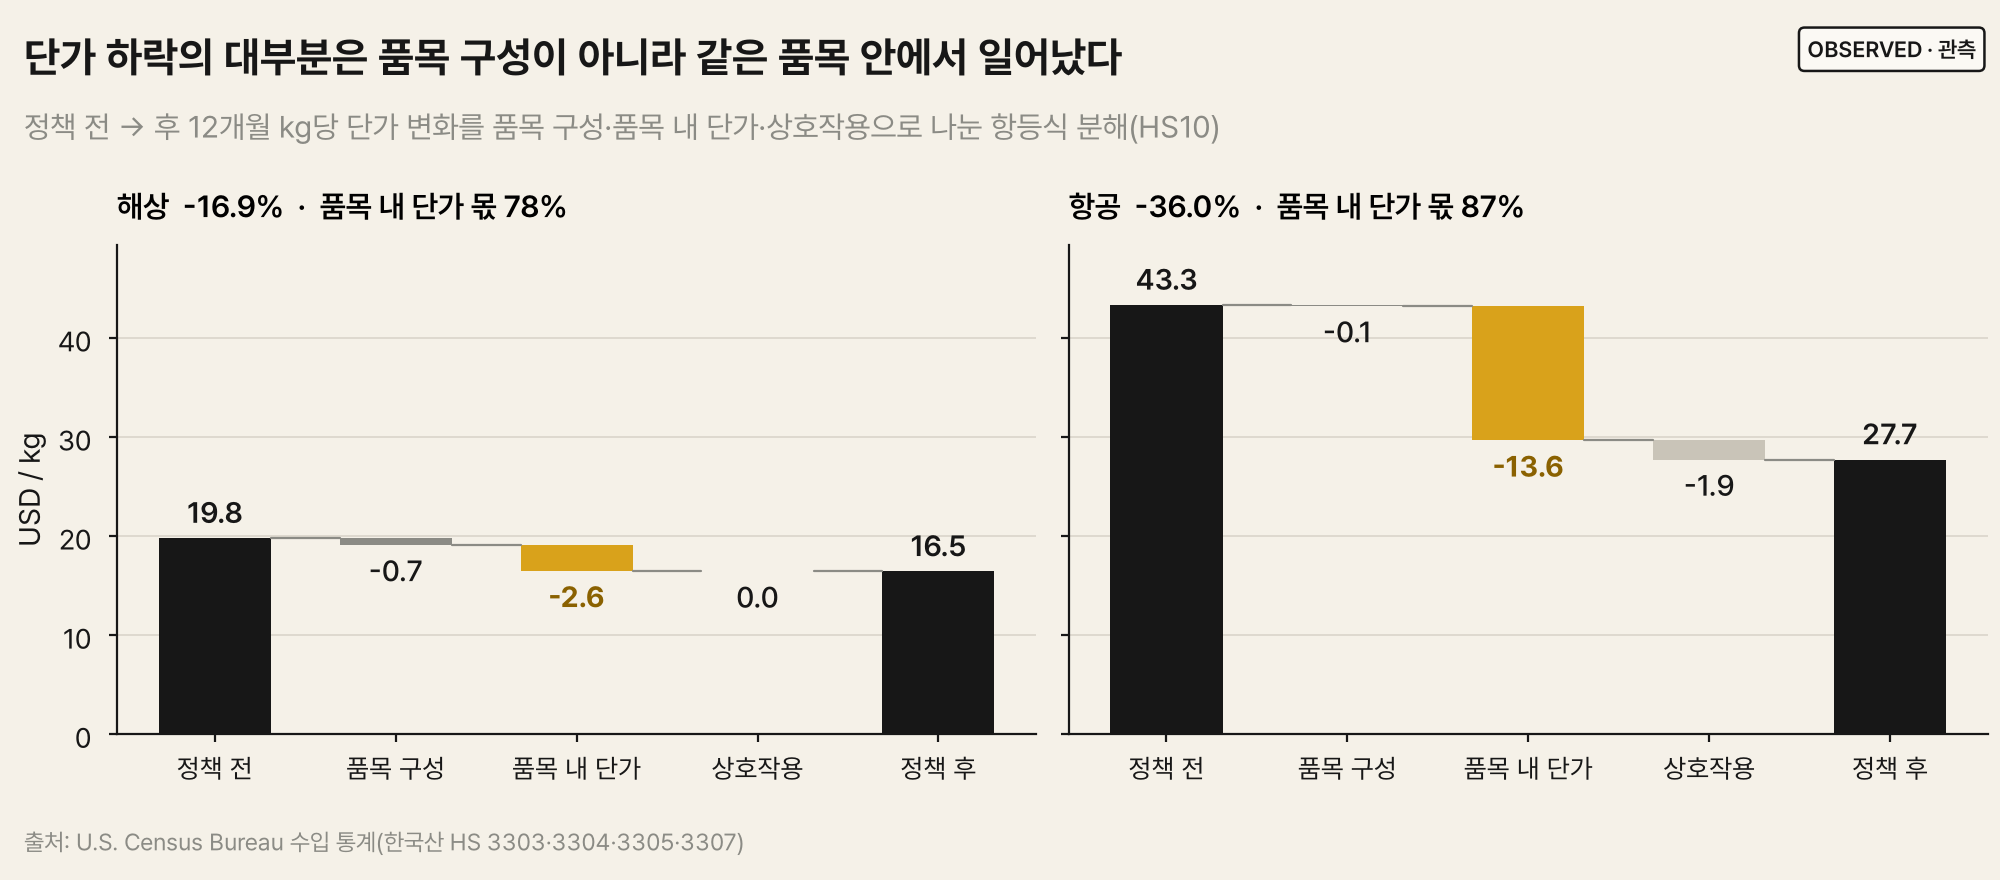

,series,dlog_usd_per_kg,dlog_lcu_per_kg,dlog_rate,fx_share_of_change
0,"US imports, vessel",-0.185,-0.143,0.042,0.227
1,"US imports, air",-0.446,-0.401,0.045,0.101
2,"US imports, sea+air",-0.219,-0.176,0.043,0.195
3,Korean exports (FOB),0.077,0.120,0.043,-0.563


,series,uv_base,uv_comp,change,mix,price,interaction
0,"Korea, HSK10",19.064,20.581,1.517,2.085,0.305,-0.872
1,"Korea, HS6",19.064,20.581,1.517,1.876,0.192,-0.551
2,"US, HS10 (sea+air)",22.387,17.987,-4.400,-0.789,-3.567,-0.044
3,"US, HS6 (sea+air)",22.387,17.987,-4.400,-0.716,-3.600,-0.085


In [10]:
show("03_unit_value_decomposition")
display(tbl("fx_decomposition")[["series", "dlog_usd_per_kg", "dlog_lcu_per_kg", "dlog_rate", "fx_share_of_change"]])
tbl("granularity_decomposition")[["series", "uv_base", "uv_comp", "change", "mix", "price", "interaction"]]

- 원화는 정책 후 약 4.3% 약해졌다(1,400 → 1,461원/달러). 이것이 미국 측 달러 단가 하락의 **10~23%만** 설명한다. 원화로 환산해도 미국 측 단가는 크게 떨어졌다.
- 한국 기록의 kg당 금액 상승(+8%)은 **비싼 품목으로의 구성 이동**(구성 효과 +2.08달러/kg)이고 품목 내 단가는 거의 그대로다(+0.30). 미국 기록은 반대로 품목 내 단가가 떨어졌다(−3.57).
- 한국의 마스크 팩 수출(정책 전 12개월 1.14억 달러)이 미국 330790 전체 수입(0.78억 달러)보다 커서, 두 나라의 세번 분류가 다르다는 것도 확인했다.
- **남는 해석**: 같은 물량을 미국이 더 낮은 가격으로 기록한다. 관세가 오른 시기에 미국 측 신고 단가만 떨어진 것은 과세가격 산정 방식의 변화를 시사한다(`INFERRED`, 확정 불가).

**설명되지 않은 변화 속에서 앞으로의 흐름은 무엇으로 가늠하나?**

### 5. 예측: 의사결정 기간에 맞는 기준선

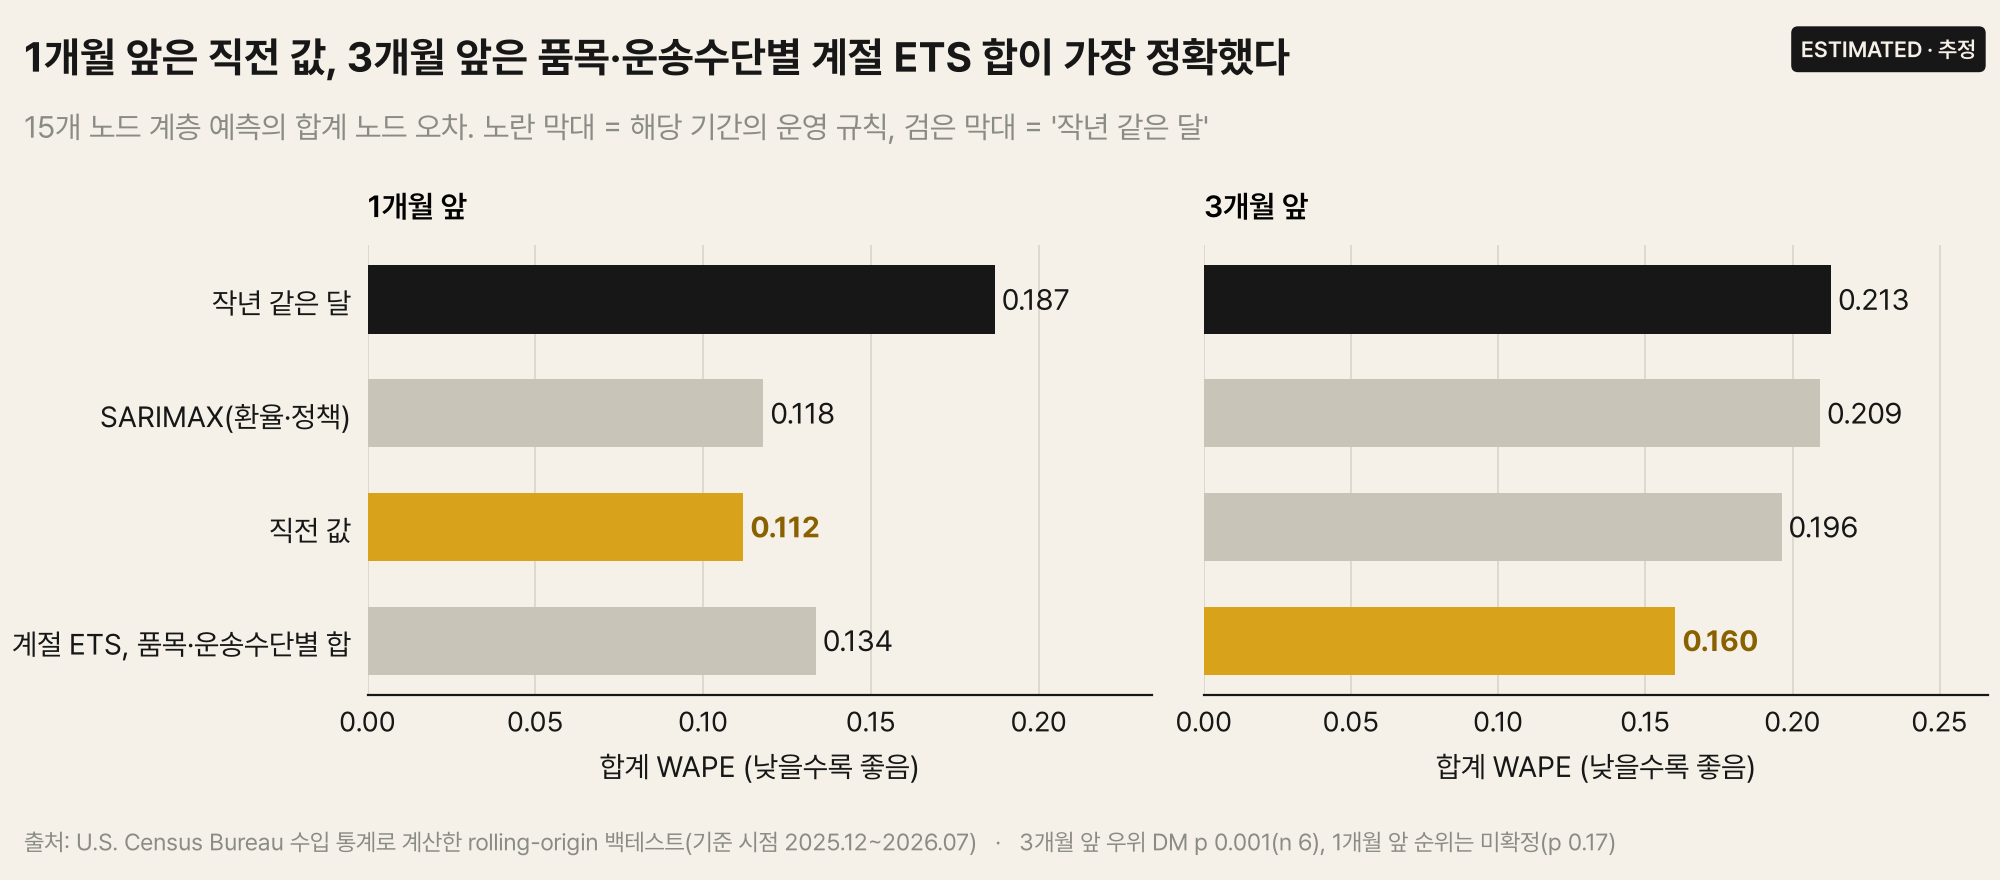

,comparison,horizon,dm_stat,p_value,n,lag0_variance
0,naive vs seasonal_naive (h1),1,-1.532,0.169,8,False
1,ets_seasonal(BU) vs seasonal_naive (h3),3,-7.449,0.001,6,False
2,naive vs ets_seasonal(BU) (h1),1,-0.651,0.536,8,False
3,ml_selected(BU) vs naive (h1),1,0.689,0.513,8,False
4,ml_selected(BU) vs ets_seasonal(BU) (h3),3,-0.173,0.870,6,True
5,[post hoc] ml_lightgbm(BU) vs naive (h1),1,-1.035,0.335,8,False
6,[post hoc] ml_xgboost(BU) vs naive (h1),1,-0.742,0.482,8,False


In [11]:
show("13_forecast_hierarchy")
tbl("forecast_dm_tests")

- 품목 4개 × 운송수단 2개, 15개 노드 계층을 2025-12~2026-07 기준 시점에서 백테스트했다. **공개 수입통계의 예측**이며 기업 수요예측이 아니다.
- 1개월 앞은 **직전 값**(합계 0.112), 3개월 앞은 **계절 ETS 합**(0.160). '작년 같은 달' 대비 3개월 앞 우위는 DM p 0.001(n 6), 1개월 앞 순위는 p 0.17로 확정되지 않는다.
- 머신러닝은 핵심 결과 2와 같다. 검증 순위와 실제 순위의 상관이 0에 가까워, 짧은 검증 구간으로는 모델을 고를 수 없었다.
- 80% 예측 구간은 실제 포함률이 71~78%로 좁다. 한국 통계(약 3주 빠름)를 선행 지표로 쓰는 예측은 이득이 없었다(양국 기록 비율이 이동 중).

**그렇다면 담당자는 무엇을 바꿔야 하나?**

### 6. 결정: 항만과 경로

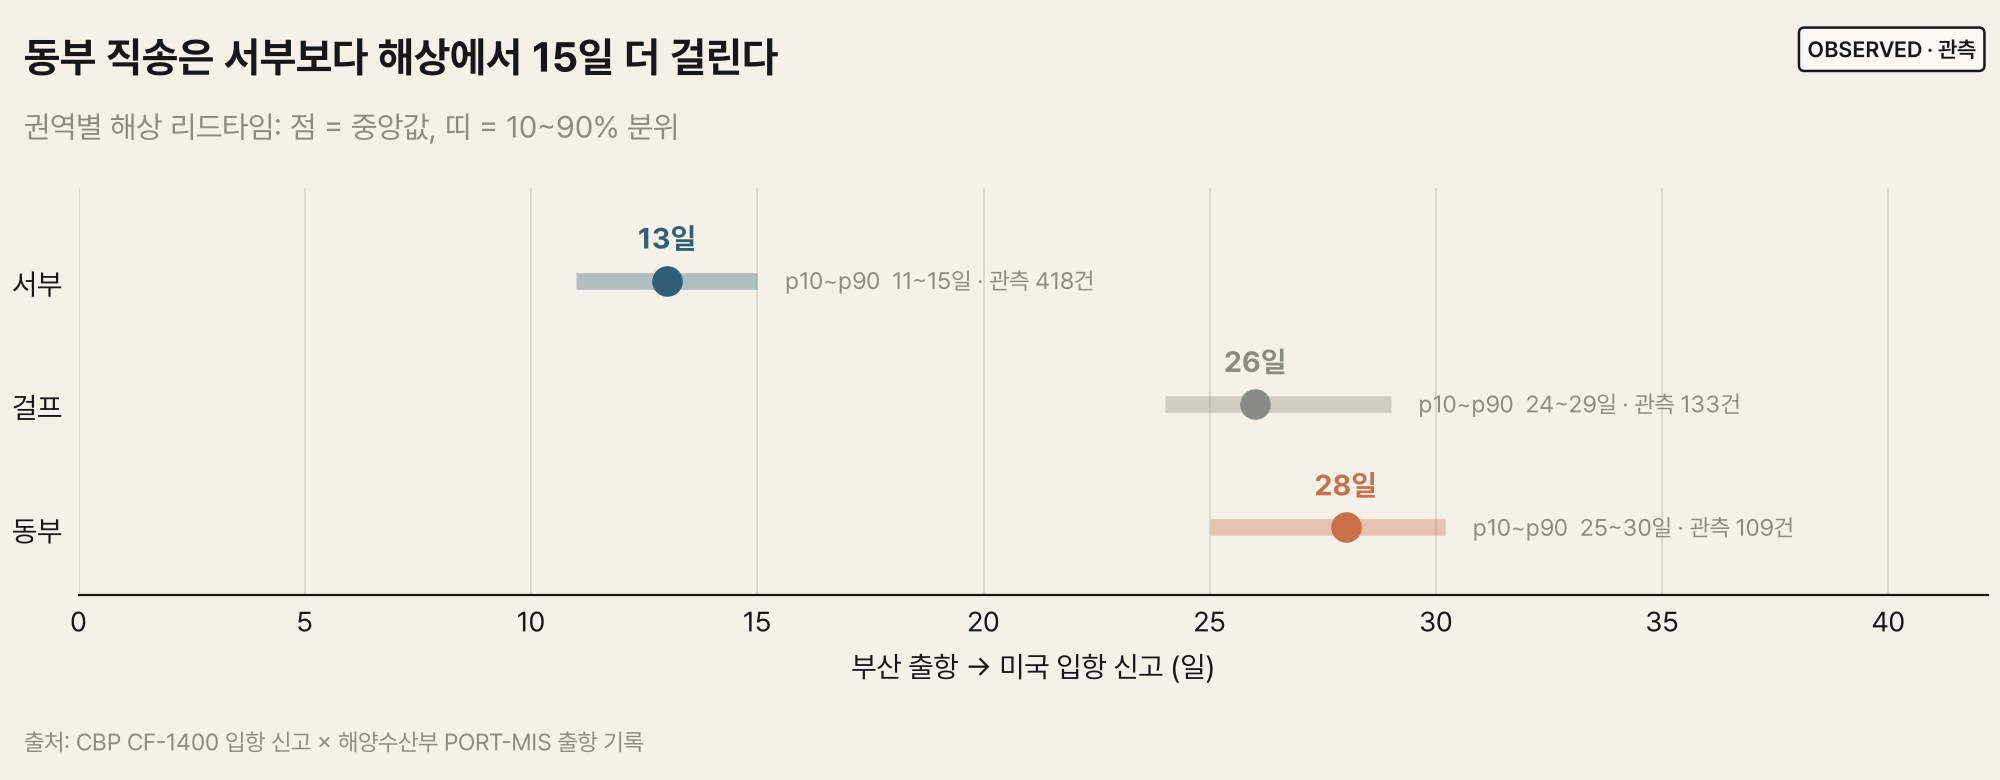

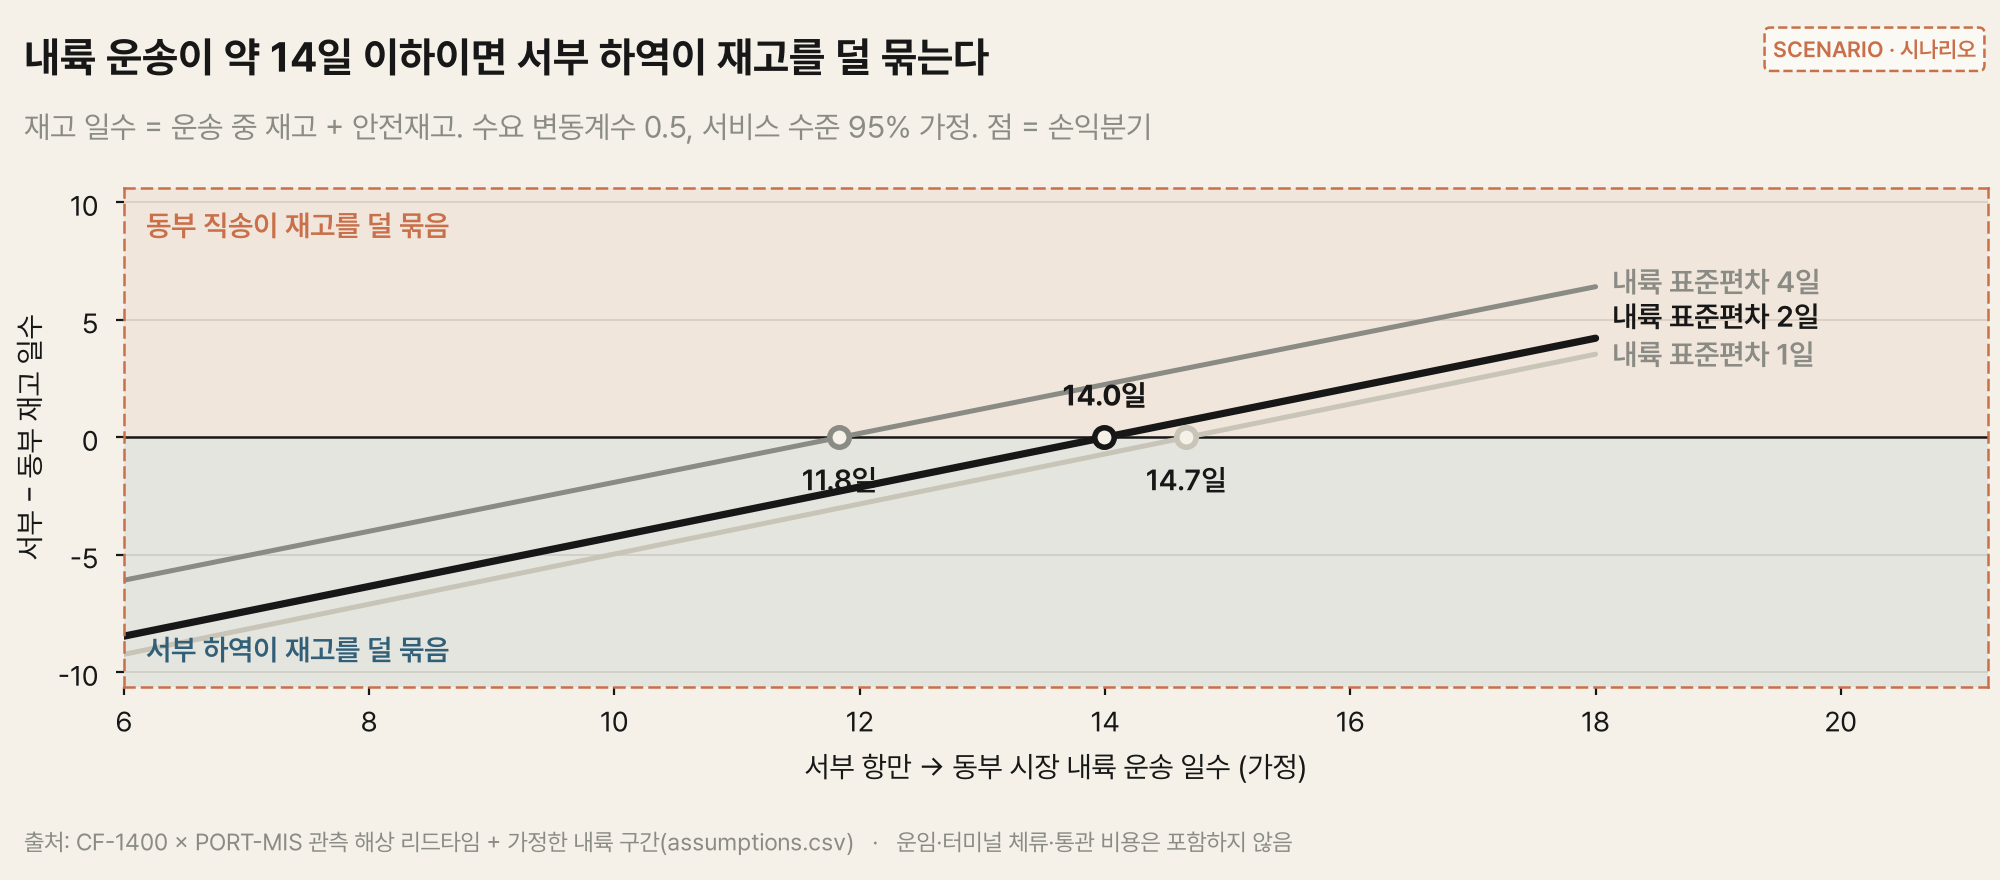

,region,median_pre,median_post,diff,ci_low,ci_high,changed
0,west_coast,13.000,13.000,0.000,0.000,0.000,False
1,gulf_coast,26.000,26.000,0.000,-1.000,1.000,False
2,east_coast,28.000,27.000,-1.000,-2.000,1.000,False


,closure_days,la_lb_share,exposed_musd
0,7,0.818,27.505
1,14,0.818,55.011
2,30,0.818,117.880


In [12]:
show("06_transit_by_region")
show("14_route_breakeven")
display(tbl("decision_q5_shift")[["region", "median_pre", "median_post", "diff", "ci_low", "ci_high", "changed"]])
tbl("decision_port_disruption").assign(exposed_musd=lambda d: d.exposed_value_usd / 1e6)[["closure_days", "la_lb_share", "exposed_musd"]]

| 결정 | 기준 | 근거 수준 |
|---|---|---|
| 하역 거점 | 해상 수입 금액의 82%가 LA·롱비치. 해상 구간은 서부 13일, 동부 28일로 14.5일 차이 | `OBSERVED` |
| 정책 영향 | 정책 후 해상 리드타임은 **변하지 않았다**(세 권역 모두 95% CI가 0 포함). 변화는 운송 구간이 아니라 통관·신고 쪽에서 일어났다 | `ESTIMATED` |
| 동부 직송 vs 서부 + 내륙 | 내륙 운송이 **약 14일 이하**면 서부 하역이 재고를 덜 묶는다. 내륙 일수가 들쑥날쑥하면 기준이 10~13일로 짧아진다 | `SCENARIO` |
| 항만 중단 대비 | LA·롱비치 2주 중단 = 해상 수입 5,500만 달러(연간의 3%) 지연 → 성수기 전 서부 창고 안전재고 2주분 이상이 기준선 | `SCENARIO` |
| 비용 | 운임·터미널 체류·통관·재고 유지 비용 | `NOT MEASURED` |

가정값과 민감도 범위는 `reports/tables/assumptions.csv`에 있다.

### 참고: 품목별 성장

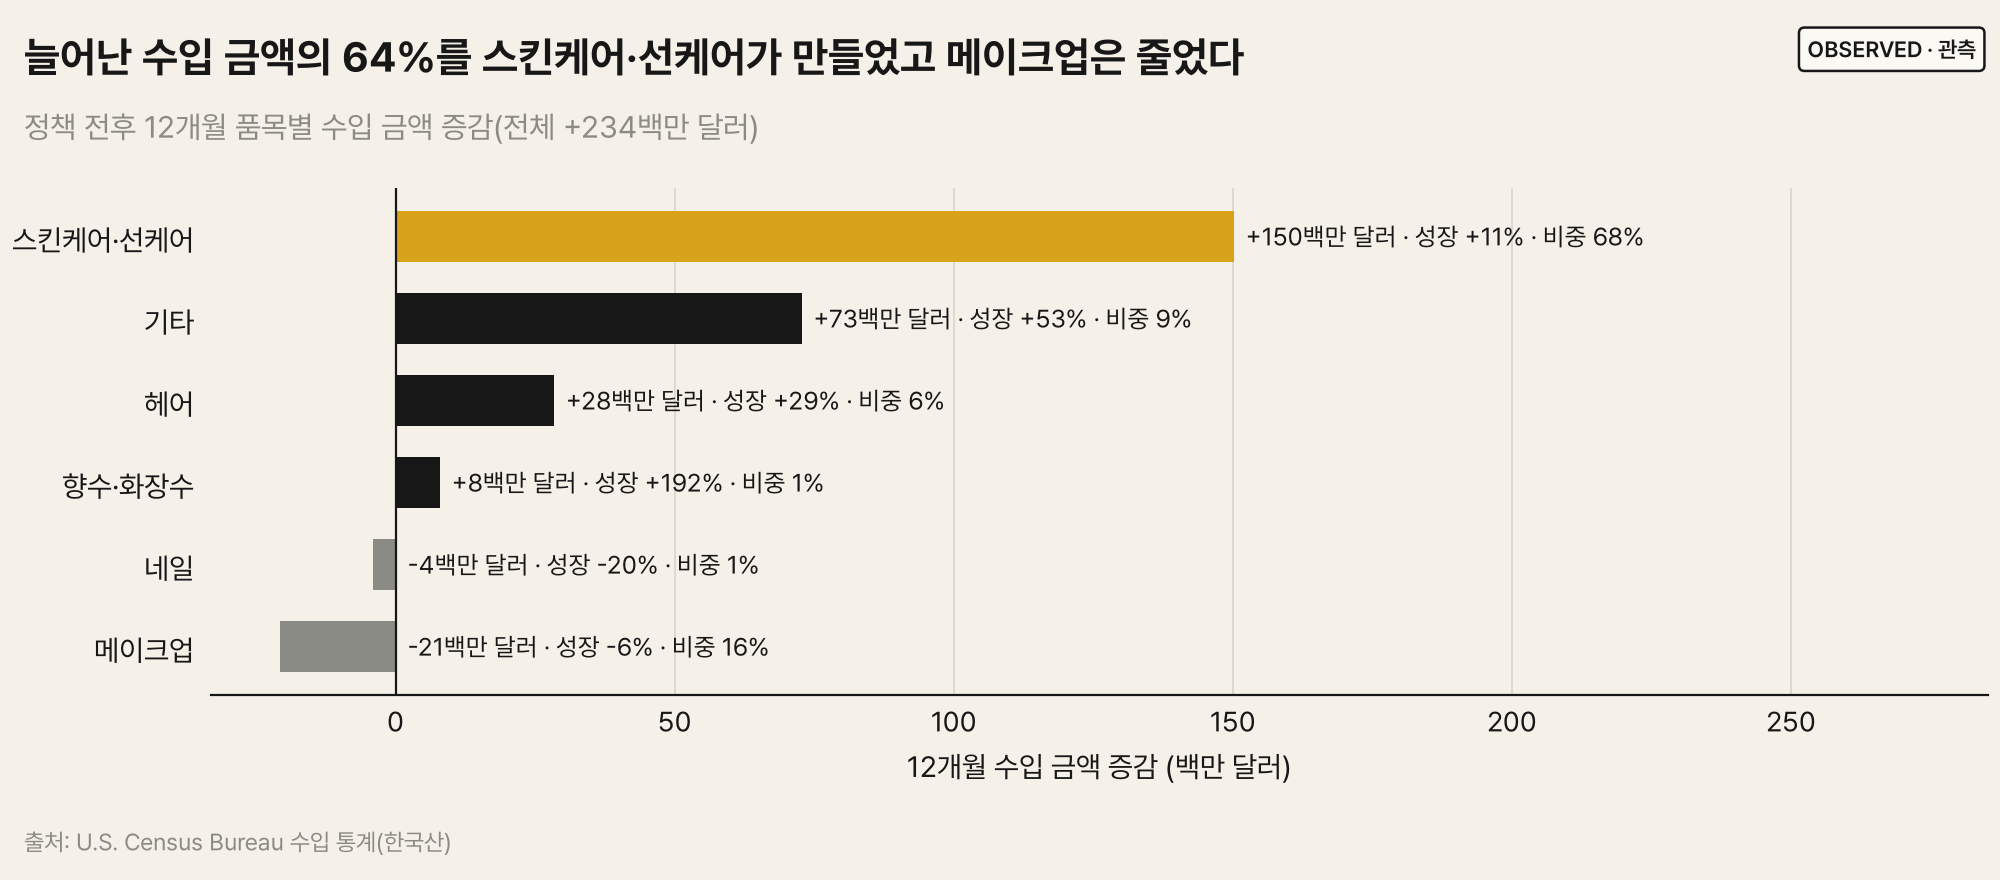

In [13]:
show("08_category_growth")

스킨케어·선케어(비중 68%)가 늘어난 금액의 대부분을 만들었고, 메이크업(16%)은 −5.5%, 네일은 −19.6%였다. 헤어(+28.8%)와 기타(+52.6%)는 작은 기반에서 빠르게 늘었다(미국 기록 기준).

## 처음 서술에서 바뀐 것

| 처음 서술 | 검증 | 고친 서술 |
|---|---|---|
| "9월 항공 단가 급락이 정책 시점과 가장 잘 맞는 한국의 신호" | 8개국 비교: 영국·프랑스·일본도 하락 | 소액면세 중단이 적용된 여러 나라의 공통 변화이며, 한국은 그중 가장 크게 떨어진 쪽 |
| "소포가 통계에 새로 잡혔는지, 운송 방식이 바뀌었는지 구분할 수 없다" | 한국 수출 통계와의 미러 분석 | 미국/한국 기록 비율이 오히려 떨어져 소포 가설은 지지되지 않음 |
| "물량은 늘고 kg당 단가는 떨어졌다(상품이 싸졌다)" | 한국 측 기록, 환율 분해 | 한국 측 kg당 금액은 올랐고, 미국 측 하락은 환율·구성으로 설명되지 않음 → 미국 측 신고 가격의 변화에 가깝다 |

바뀐 이유는 모두 [사전 등록 변경 기록](../docs/preregistration.md)에 있다.

## 데이터와 재현성

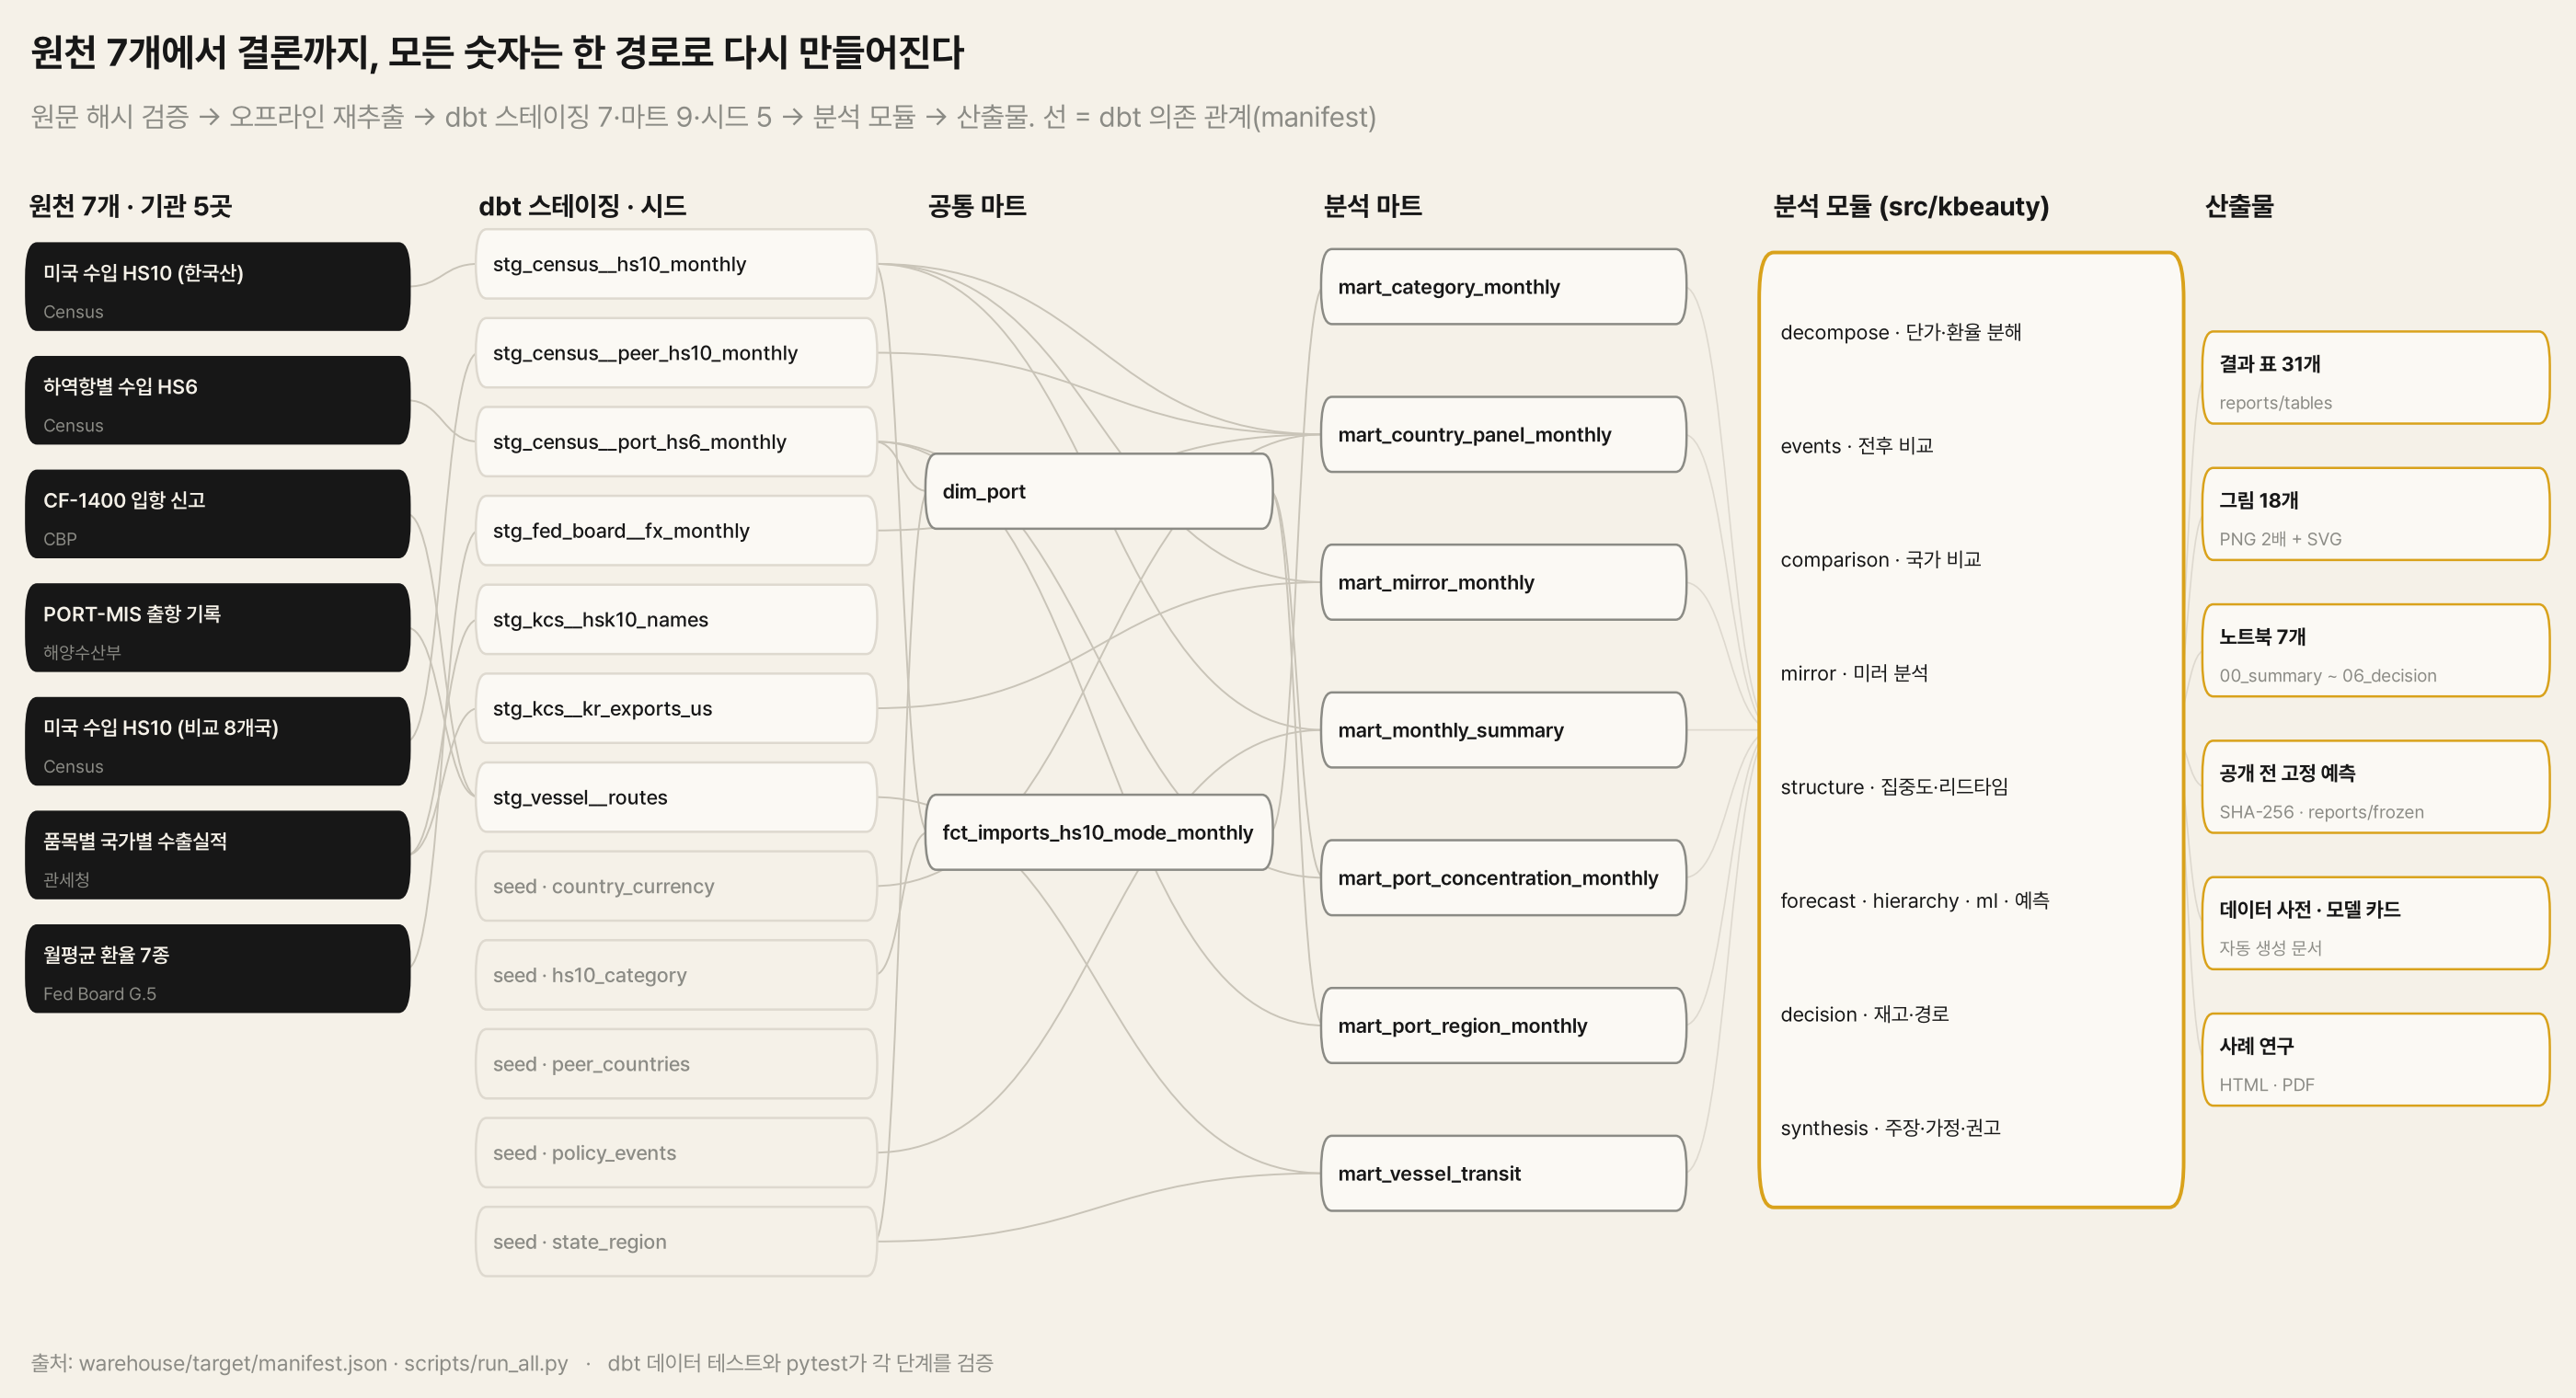

In [14]:
show("00_data_lineage")

| # | 원천 | 기관 | 단위 | 용도 |
|---|---|---|---|---|
| 1 | [수입 통계 `imports/hs`](https://api.census.gov/data/timeseries/intltrade/imports/hs.html) (한국산) | 미국 Census | HS10 × 월 | 물량·금액·단가 |
| 2 | [수입 통계 `imports/porths`](https://api.census.gov/data/timeseries/intltrade/imports/porths.html) (한국산) | 미국 Census | 하역항 × HS6 × 월 | 하역항 집중도 |
| 3 | [CF-1400 외국 무역선 입항 기록](https://www.cbp.gov/document/report/cf-1400-record-vessel-foreign-trade-entrances) | 미국 CBP | 선박 1회 입항 | 리드타임(4와 연결) |
| 4 | [PORT-MIS 선박운항정보](https://www.data.go.kr/data/15006353/openapi.do) | 해양수산부 | 선박 1회 출항 | 리드타임(3과 연결) |
| 5 | [수입 통계 `imports/hs`](https://api.census.gov/data/timeseries/intltrade/imports/hs.html) (비교 8개국) | 미국 Census | 국가 × HS10 × 월 | 국가 비교 |
| 6 | [품목별 국가별 수출입실적(GW)](https://www.data.go.kr/data/15100475/openapi.do) | 관세청 | HSK10 × 월 | 미러 분석, 한국 측 세목 |
| 7 | 월평균 환율 7개 통화([G.5](https://www.federalreserve.gov/releases/h10/current/default.htm), 릴리스 XML) | Federal Reserve Board | 통화 × 월 | 환율 통제·분해 |

- **원문 보관 → 해시 → 오프라인 재추출 → dbt 테스트**: API 응답 원문과 추출 CSV 88개 파일의 SHA-256을 기록하고, 원문만으로 다시 만든 CSV가 저장본과 바이트 단위로 같은지 매번 확인한다. dbt 데이터 테스트 49개(하역항 합계 = 전국 합계, 패널 균형, 미러 합계 보존 등), pytest 78개.
- 비교 창: 정책 전후 **같은 계절의 12개월**(2024.09~2025.08 vs 2025.09~2026.08). 금액은 미국 관세 신고 가격, 중량은 해상·항공만 공개된다.
- 열 정의는 [데이터 사전](../reports/data_dictionary.csv), 예측 설계와 결과는 [모델 카드](../reports/model_card.md), 전체 설계는 [프로젝트 계획](../docs/PROJECT_PLAN.md)에 있다.

## 한계

- 원인은 확정하지 않았다. 미국 측 신고 가격 하락의 원인(과세가격 산정 방식 등)은 통관 단위 자료 없이는 검증할 수 없는 가설이다.
- 정책 이후 12개월, 비교국 6~8개라 검출 한계가 크다. 환율·미국 수요·유통 채널 같은 동시 요인을 완전히 배제하지 못했다.
- 한국 수출 통계에는 운송수단 구분이 없고, 두 나라의 세번 분류가 일부 다르다(마스크 팩 등). 그래서 세목보다 전체 합계 비교를 주 지표로 썼다.
- 리드타임은 '부산 출항 → 미국 입항 신고'까지이며, 통관·내륙 운송은 시나리오로만 다뤘다.
- 예측 백테스트의 기준 시점은 8개(3개월 앞 6개)뿐이고, 공개 전 고정 예측은 아직 채점되지 않았다.

## 부록

같은 저자가 이 공개 데이터를 기준값으로 만든 **합성 운영 데이터(27개 표, 132만 행)의** 검증(해시 47개, 검사 219개 중 실패 0, 사전 가설 6개)은
[`appendix/synthetic_data_validation`](../appendix/synthetic_data_validation/README.md)에 있다. 합성 데이터로는 '설계대로 만들어졌는가'만 판단하고, 시장 결론은 실제 데이터에서만 낸다.